# TDE 04 – Modelo Final: Avaliação de Compra de Produto Bancário (Bank Marketing)

**Métrica principal:** F1-score da classe positiva (`y = 1`, cliente que contratou o depósito a prazo).

## 1. Contextualização e objetivo desta etapa

Este notebook dá continuidade ao **TDE 01** (análise exploratória) e ao **TDE 03** (baseline). O objetivo é comparar o baseline com modelos que tratam o desbalanceamento, incluir **SVM** e **Rede Neural (MLP)** e experimentar algoritmos adicionais, como **XGBoost** e **LightGBM**.

### Achados anteriores considerados

| Achado | Decisão na modelagem |
|---|---|
| Aproximadamente 11,3% de `yes` | Usar F1 como métrica principal; não interpretar acurácia isoladamente. |
| `duration` só é conhecida depois da ligação | Removida dos modelos oficiais para evitar vazamento de informação. |
| `poutcome = success` tem alta conversão | Mantida como variável preditora, respeitando o momento de uso do modelo. |
| Variáveis macroeconômicas estão associadas à conversão | Mantidas para que os modelos possam explorar esses sinais. |

### O que será comparado

1. Modelos com tratamento de desbalanceamento: Regressão Logística, Random Forest, SVM, XGBoost e LightGBM.
2. Rede Neural MLP.
3. Ajuste de hiperparâmetros de XGBoost e LightGBM por validação cruzada.
4. Experimento adicional com `RandomOverSampler`, aplicado dentro do pipeline.
5. Otimização do limiar de decisão usando exclusivamente previsões *out-of-fold* do conjunto de treino.
6. Comparação com o baseline do TDE 03 e análise de importância das variáveis.

**Regra metodológica central:** o conjunto de teste não será usado para escolher modelos, hiperparâmetros ou limiares. Ele será utilizado somente para a avaliação final, depois que as decisões forem tomadas com o conjunto de treino e a validação cruzada.


In [1]:
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import (
    train_test_split, StratifiedKFold, cross_validate,
    cross_val_predict, RandomizedSearchCV
)
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.neural_network import MLPClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score, confusion_matrix,
    ConfusionMatrixDisplay, classification_report,
    roc_curve, precision_recall_curve, make_scorer
)

from imblearn.over_sampling import RandomOverSampler
from imblearn.pipeline import Pipeline as ImbPipeline

import xgboost as xgb
from lightgbm import LGBMClassifier

# Mantém avisos úteis (por exemplo, convergência da MLP), ignorando apenas FutureWarning.
warnings.filterwarnings("ignore", category=FutureWarning)
SEED = 42
np.random.seed(SEED)

sns.set_theme(style="whitegrid")
plt.rcParams["font.sans-serif"] = "DejaVu Sans"
plt.rcParams["axes.edgecolor"] = "#cccccc"
plt.rcParams["axes.linewidth"] = 0.8

print("Bibliotecas carregadas com sucesso.")
print(f"Versões: pandas={pd.__version__}, NumPy={np.__version__}")


Bibliotecas carregadas com sucesso.
Versões: pandas=2.2.3, NumPy=2.4.6


## 2. Carregamento dos dados

Use o mesmo arquivo `bank-additional-full.csv` dos TDEs anteriores. No Colab, o notebook tenta acessar o Google Drive. Localmente, procura o arquivo na pasta do notebook ou em `data/`.

Dependências externas utilizadas: `imbalanced-learn`, `xgboost` e `lightgbm`. Caso faltem no ambiente local, instale-as com `pip install imbalanced-learn xgboost lightgbm`.


In [2]:
# Carregamento compatível com Google Colab e execução local.
try:
    from google.colab import drive
    drive.mount("/content/drive")
    candidatos = [Path("/content/drive/MyDrive/bank-additional-full.csv")]
except ImportError:
    candidatos = [
        Path("bank-additional-full.csv"),
        Path("data/bank-additional-full.csv"),
    ]

caminho_arquivo = next((p for p in candidatos if p.exists()), None)
if caminho_arquivo is None:
    caminhos = "\n".join(str(p) for p in candidatos)
    raise FileNotFoundError(
        "Não encontrei 'bank-additional-full.csv'. Coloque o arquivo na pasta do notebook "
        "(ou em ./data/) ou ajuste `candidatos`. Locais verificados:\n" + caminhos
    )

df_raw = pd.read_csv(caminho_arquivo, sep=";")
print(f"Dados carregados: {df_raw.shape[0]} linhas × {df_raw.shape[1]} colunas")
print("Distribuição original do alvo:")
print(df_raw["y"].value_counts(normalize=True).round(4))
display(df_raw.head())


Mounted at /content/drive
Dados carregados: 41188 linhas × 21 colunas
Distribuição original do alvo:
y
no     0.8873
yes    0.1127
Name: proportion, dtype: float64


,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
2,37,services,married,high.school,no,yes,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
4,56,services,married,high.school,no,no,yes,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no


## 3. Preparação e engenharia de atributos

Decisões tomadas a partir da EDA e do baseline:

1. **Remoção de `duration`:** a duração só é conhecida depois da chamada; seu uso produziria vazamento para o objetivo de selecionar clientes antes do contato.
2. **Tratamento de `pdays`:** 999 representa ausência de contato anterior. Criamos `contatado_antes` e substituímos 999 por 0 para não interpretar 999 como uma quantidade real de dias.
3. **Remoção de duplicatas:** evita que registros repetidos influenciem artificialmente o treinamento e a avaliação.
4. **Categorias `unknown`:** mantidas como uma categoria própria, seguindo a decisão do TDE 03.
5. **Alvo binário:** `yes` → 1 e `no` → 0.

**Nota sobre o uso em produção:** a disponibilidade de variáveis como `campaign` depende do instante em que a previsão será feita. Antes de uma campanha começar, algumas informações acumuladas durante a própria campanha podem ainda não existir. A aplicação real deve definir esse instante e revisar as variáveis disponíveis nele.


In [3]:
df = df_raw.copy()

# 1) Remover duplicatas
n_dup = int(df.duplicated().sum())
df = df.drop_duplicates().reset_index(drop=True)
print(f"Duplicatas removidas: {n_dup} | Linhas restantes: {len(df)}")

# 2) Remover duration (target leakage)
if "duration" in df.columns:
    df = df.drop(columns=["duration"])

# 3) Tratar pdays = 999 (nunca contatado anteriormente)
df["contatado_antes"] = (df["pdays"] != 999).astype(int)
df.loc[df["pdays"] == 999, "pdays"] = 0

# 4) Codificar o alvo
if not set(df["y"].dropna().unique()).issubset({"yes", "no"}):
    raise ValueError("A coluna y contém valores diferentes de 'yes' e 'no'. Verifique a base.")
df["y"] = (df["y"] == "yes").astype(int)

X = df.drop(columns=["y"])
y = df["y"]

num_cols = X.select_dtypes(include=[np.number]).columns.tolist()
cat_cols = X.select_dtypes(include=["object", "category"]).columns.tolist()

print(f"\nFeatures numéricas ({len(num_cols)}): {num_cols}")
print(f"Features categóricas ({len(cat_cols)}): {cat_cols}")
print(f"Proporção da classe positiva: {y.mean():.2%}")


Duplicatas removidas: 12 | Linhas restantes: 41176

Features numéricas (10): ['age', 'campaign', 'pdays', 'previous', 'emp.var.rate', 'cons.price.idx', 'cons.conf.idx', 'euribor3m', 'nr.employed', 'contatado_antes']
Features categóricas (10): ['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'day_of_week', 'poutcome']
Proporção da classe positiva: 11.27%


## 4. Divisão treino / teste estratificada

80% treino / 20% teste, estratificada para preservar a proporção de ~11% de positivos.

In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=SEED
)

print(f"Treino : {X_train.shape[0]} amostras  |  positivos: {y_train.mean():.3f}")
print(f"Teste  : {X_test.shape[0]} amostras  |  positivos: {y_test.mean():.3f}")

Treino : 32940 amostras  |  positivos: 0.113
Teste  : 8236 amostras  |  positivos: 0.113


## 5. Pré-processamento

As transformações ficam dentro dos pipelines. Assim, em cada fold da validação cruzada, o scaler e o encoder são ajustados somente com a parte de treino daquele fold.

- Numéricas: `StandardScaler`.
- Categóricas: `OneHotEncoder(handle_unknown="ignore")`.
- A saída é densa para manter compatibilidade com a MLP e os modelos utilizados neste notebook.

O código abaixo mantém compatibilidade com versões antigas e novas do scikit-learn (`sparse` / `sparse_output`).


In [5]:
def make_preprocessor():
    try:
        encoder = OneHotEncoder(handle_unknown="ignore", sparse_output=False)
    except TypeError:  # compatibilidade com scikit-learn anterior a 1.2
        encoder = OneHotEncoder(handle_unknown="ignore", sparse=False)

    return ColumnTransformer(
        transformers=[
            ("num", StandardScaler(), num_cols),
            ("cat", encoder, cat_cols),
        ],
        remainder="drop",
        sparse_threshold=0,
    )

print("Pré-processador definido.")


Pré-processador definido.


## 6. Definição dos modelos

| Modelo | Estratégia | Papel no projeto |
|---|---|---|
| Regressão Logística | `class_weight="balanced"` | Evolução do baseline |
| Random Forest | `class_weight="balanced"` | Evolução do baseline |
| SVM (RBF) | `class_weight="balanced"` | Exigência do enunciado |
| MLP | Rede neural com duas camadas ocultas | Exigência do enunciado |
| XGBoost | `scale_pos_weight` | Modelo adicional |
| LightGBM | `is_unbalance=True` | Modelo adicional |

Os algoritmos serão avaliados com a mesma divisão treino/teste e o mesmo pré-processamento. A validação cruzada é feita exclusivamente no conjunto de treino.


In [6]:
# Razão entre a classe majoritária e a minoritária, calculada somente no treino.
scale_pos = (y_train == 0).sum() / (y_train == 1).sum()
print(f"scale_pos_weight (XGBoost): {scale_pos:.2f}")

modelos = {
    "Logistic (balanced)": Pipeline([
        ("pre", make_preprocessor()),
        ("clf", LogisticRegression(
            class_weight="balanced", max_iter=1500, random_state=SEED, n_jobs=1
        )),
    ]),
    "Random Forest (balanced)": Pipeline([
        ("pre", make_preprocessor()),
        ("clf", RandomForestClassifier(
            class_weight="balanced", n_estimators=200, random_state=SEED, n_jobs=1
        )),
    ]),
    "SVM (RBF balanced)": Pipeline([
        ("pre", make_preprocessor()),
        ("clf", SVC(
            kernel="rbf", class_weight="balanced", probability=True,
            random_state=SEED, cache_size=1000
        )),
    ]),
    "MLP (Rede Neural)": Pipeline([
        ("pre", make_preprocessor()),
        ("clf", MLPClassifier(
            hidden_layer_sizes=(128, 64), activation="relu",
            max_iter=300, early_stopping=True, random_state=SEED
        )),
    ]),
    "XGBoost": Pipeline([
        ("pre", make_preprocessor()),
        ("clf", xgb.XGBClassifier(
            scale_pos_weight=scale_pos, eval_metric="logloss",
            random_state=SEED, n_jobs=1, verbosity=0
        )),
    ]),
    "LightGBM": Pipeline([
        ("pre", make_preprocessor()),
        ("clf", LGBMClassifier(
            is_unbalance=True, random_state=SEED, n_jobs=1, verbosity=-1
        )),
    ]),
}

print(f"{len(modelos)} modelos definidos.")


scale_pos_weight (XGBoost): 7.88
6 modelos definidos.


## 7. Validação cruzada estratificada (5 folds)

A validação cruzada estima o desempenho no conjunto de treino e permite comparar modelos sem consultar o conjunto de teste. Reportamos F1 médio e desvio-padrão, além de precisão, recall e ROC-AUC.


In [7]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
scoring = {
    "f1": "f1",
    "precision": make_scorer(precision_score, zero_division=0),
    "recall": make_scorer(recall_score, zero_division=0),
    "roc_auc": "roc_auc",
}

cv_results = {}
print("Executando validação cruzada (pode levar alguns minutos)...\n")

for nome, pipe in modelos.items():
    scores = cross_validate(
        pipe, X_train, y_train,
        cv=cv, scoring=scoring, n_jobs=-1,
        return_train_score=False,
    )
    cv_results[nome] = {
        "F1": scores["test_f1"].mean(),
        "F1_std": scores["test_f1"].std(),
        "Precisão": scores["test_precision"].mean(),
        "Recall": scores["test_recall"].mean(),
        "ROC-AUC": scores["test_roc_auc"].mean(),
    }
    print(
        f"{nome:25s} | F1 = {scores['test_f1'].mean():.3f} "
        f"± {scores['test_f1'].std():.3f} | ROC-AUC = {scores['test_roc_auc'].mean():.3f}"
    )

df_cv = pd.DataFrame(cv_results).T.sort_values("F1", ascending=False)
cv_scores_final = df_cv["F1"].to_dict()
print("\nRanking por F1 na validação cruzada:")
display(df_cv.round(3))


Executando validação cruzada (pode levar alguns minutos)...

Logistic (balanced)       | F1 = 0.450 ± 0.008 | ROC-AUC = 0.791
Random Forest (balanced)  | F1 = 0.367 ± 0.006 | ROC-AUC = 0.775


/usr/local/lib/python3.13/dist-packages/joblib/externals/loky/process_executor.py:787: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(


SVM (RBF balanced)        | F1 = 0.472 ± 0.011 | ROC-AUC = 0.777
MLP (Rede Neural)         | F1 = 0.354 ± 0.030 | ROC-AUC = 0.788
XGBoost                   | F1 = 0.442 ± 0.009 | ROC-AUC = 0.766
LightGBM                  | F1 = 0.473 ± 0.010 | ROC-AUC = 0.797

Ranking por F1 na validação cruzada:


,F1,F1_std,Precisão,Recall,ROC-AUC
LightGBM,0.473,0.010,0.381,0.621,0.797
SVM (RBF balanced),0.472,0.011,0.386,0.609,0.777
Logistic (balanced),0.450,0.008,0.353,0.622,0.791
XGBoost,0.442,0.009,0.362,0.567,0.766
Random Forest (balanced),0.367,0.006,0.545,0.276,0.775
MLP (Rede Neural),0.354,0.030,0.640,0.247,0.788


## 8. Avaliação dos modelos no conjunto de teste (limiar 0,5)

Depois da validação cruzada, cada pipeline é ajustado com todo o conjunto de treino e avaliado no teste. O conjunto de teste permanece reservado: seus resultados não serão usados para escolher hiperparâmetros ou limiares.


In [8]:
def calcular_metricas(y_true, y_proba, threshold=0.5):
    """Calcula métricas a partir das probabilidades e de um limiar definido previamente."""
    y_pred = (np.asarray(y_proba) >= threshold).astype(int)
    return {
        "Acurácia": accuracy_score(y_true, y_pred),
        "Precisão": precision_score(y_true, y_pred, zero_division=0),
        "Recall": recall_score(y_true, y_pred, zero_division=0),
        "F1": f1_score(y_true, y_pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_true, y_proba),
        "PR-AUC": average_precision_score(y_true, y_proba),
    }

resultados = []
preds = {}
probas = {}
treinados = {}

for nome, pipe in modelos.items():
    pipe.fit(X_train, y_train)
    y_proba = pipe.predict_proba(X_test)[:, 1]
    y_pred = (y_proba >= 0.5).astype(int)

    preds[nome] = y_pred
    probas[nome] = y_proba
    treinados[nome] = pipe
    resultados.append({"Modelo": nome, **calcular_metricas(y_test, y_proba, 0.5)})

df_res = pd.DataFrame(resultados).set_index("Modelo").sort_values("F1", ascending=False)
print("Resultados no conjunto de teste (limiar 0,5):")
display(df_res.style.format("{:.3f}").background_gradient(subset=["F1", "ROC-AUC", "PR-AUC"], cmap="YlGn"))


Resultados no conjunto de teste (limiar 0,5):


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


,Acurácia,Precisão,Recall,F1,ROC-AUC,PR-AUC
Modelo,,,,,,
LightGBM,0.849,0.397,0.644,0.491,0.808,0.487
Logistic (balanced),0.830,0.359,0.645,0.462,0.800,0.446
XGBoost,0.841,0.373,0.606,0.461,0.788,0.454
Random Forest (balanced),0.893,0.546,0.287,0.376,0.782,0.422
MLP (Rede Neural),0.900,0.687,0.208,0.319,0.797,0.467
SVM (RBF balanced),0.887,0.489,0.072,0.126,0.785,0.396


### 8.1 Comparação visual das métricas

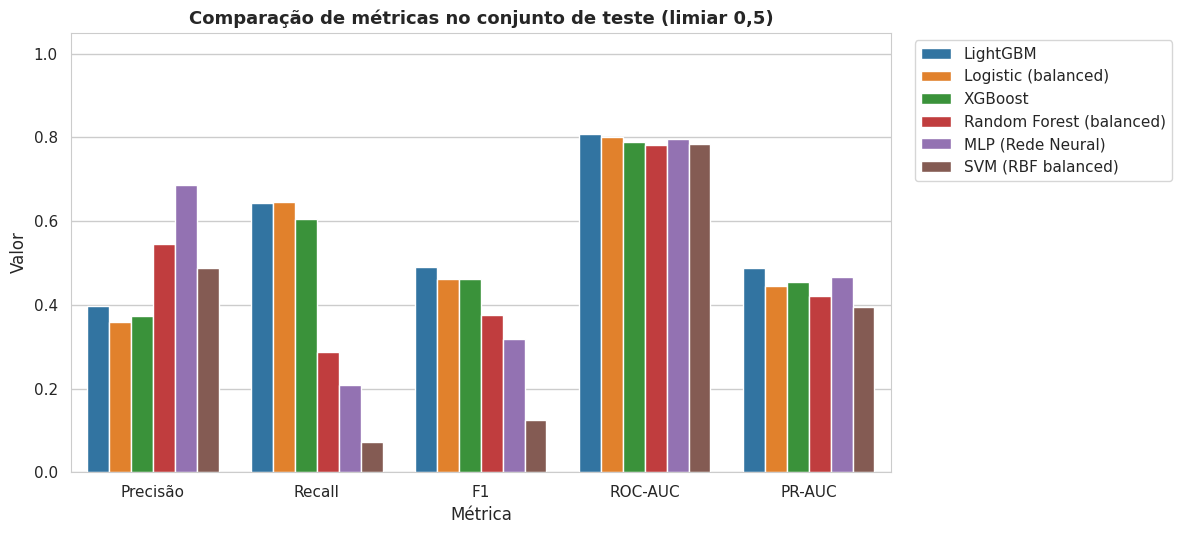

In [9]:
metricas_plot = ["Precisão", "Recall", "F1", "ROC-AUC", "PR-AUC"]
df_plot = df_res[metricas_plot].reset_index().melt(id_vars="Modelo", var_name="Métrica", value_name="Valor")

plt.figure(figsize=(12, 5.5))
sns.barplot(data=df_plot, x="Métrica", y="Valor", hue="Modelo", palette="tab10")
plt.title("Comparação de métricas no conjunto de teste (limiar 0,5)", fontsize=13, fontweight="bold")
plt.ylim(0, 1.05)
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

### 8.2 Matrizes de confusão

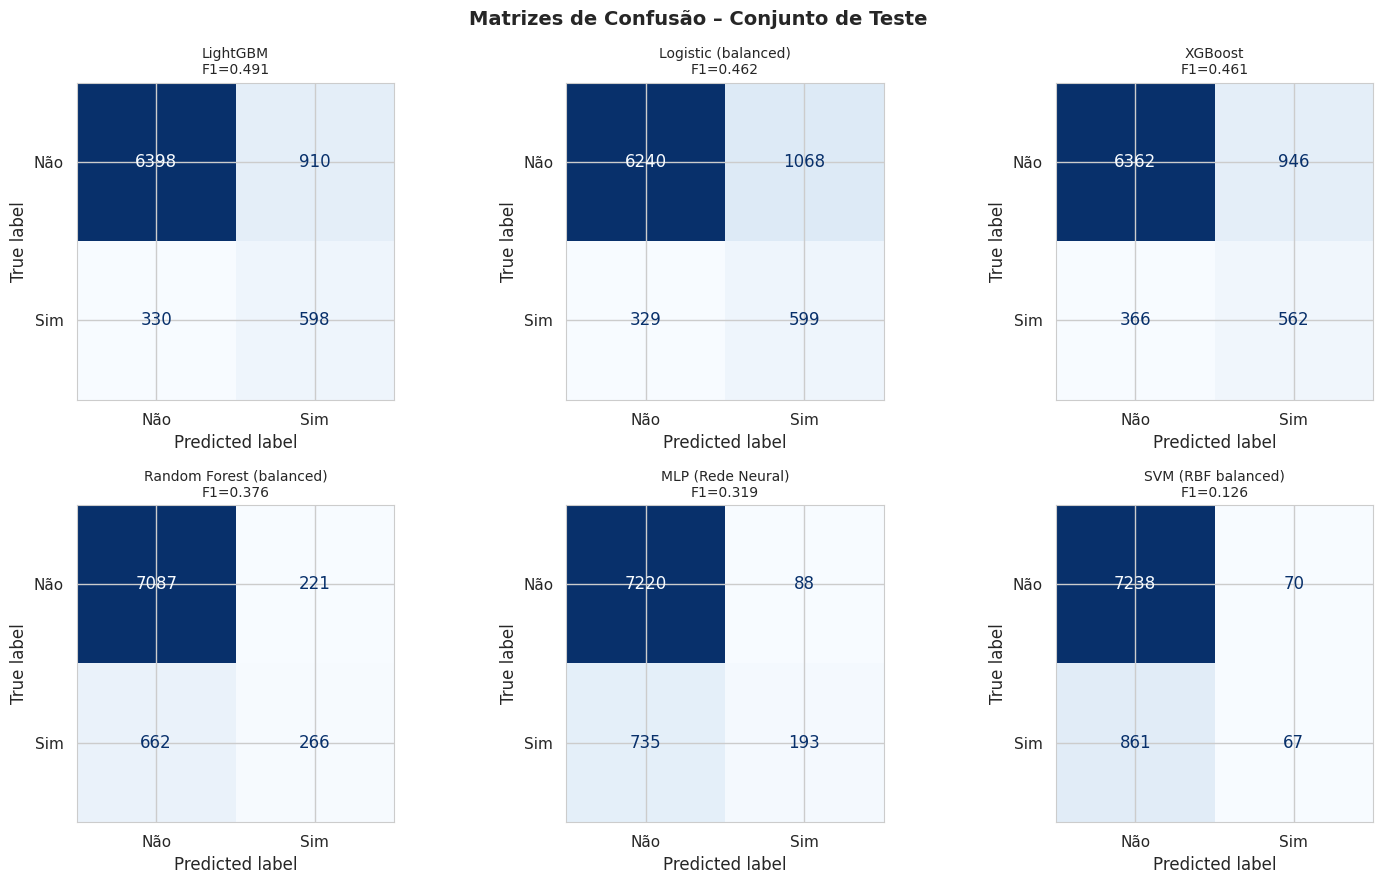

In [10]:
nomes = list(df_res.index)
fig, axes = plt.subplots(2, 3, figsize=(15, 9))
for ax, nome in zip(axes.ravel(), nomes):
    cm = confusion_matrix(y_test, preds[nome])
    ConfusionMatrixDisplay(cm, display_labels=["Não", "Sim"]).plot(ax=ax, colorbar=False, cmap="Blues")
    ax.set_title(f"{nome}\nF1={df_res.loc[nome, 'F1']:.3f}", fontsize=10)
plt.suptitle("Matrizes de Confusão – Conjunto de Teste", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()

### 8.3 Curvas ROC e Precisão-Recall

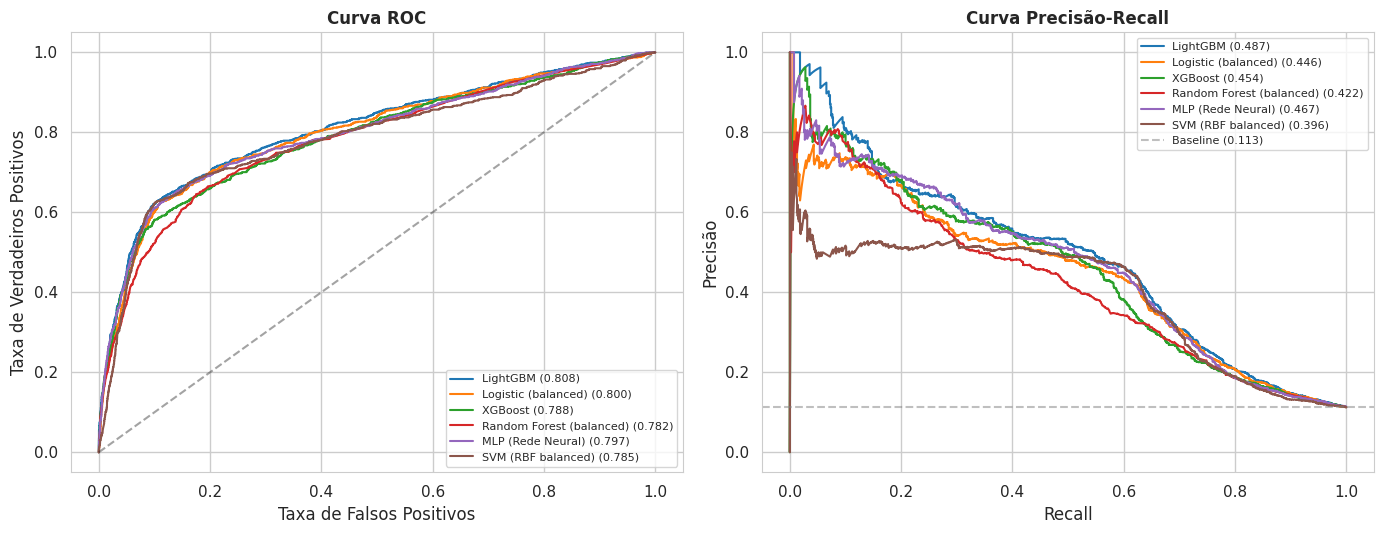

In [11]:
cores = dict(zip(nomes, sns.color_palette("tab10", len(nomes))))
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

# ROC
for nome in nomes:
    fpr, tpr, _ = roc_curve(y_test, probas[nome])
    axes[0].plot(fpr, tpr, label=f"{nome} ({df_res.loc[nome, 'ROC-AUC']:.3f})", color=cores[nome])
axes[0].plot([0, 1], [0, 1], "k--", alpha=0.4)
axes[0].set_title("Curva ROC", fontweight="bold")
axes[0].set_xlabel("Taxa de Falsos Positivos")
axes[0].set_ylabel("Taxa de Verdadeiros Positivos")
axes[0].legend(loc="lower right", fontsize=8)

# PR
for nome in nomes:
    prec, rec, _ = precision_recall_curve(y_test, probas[nome])
    axes[1].plot(rec, prec, label=f"{nome} ({df_res.loc[nome, 'PR-AUC']:.3f})", color=cores[nome])
axes[1].axhline(y_test.mean(), color="gray", ls="--", alpha=0.5, label=f"Baseline ({y_test.mean():.3f})")
axes[1].set_title("Curva Precisão-Recall", fontweight="bold")
axes[1].set_xlabel("Recall")
axes[1].set_ylabel("Precisão")
axes[1].legend(loc="upper right", fontsize=8)

plt.tight_layout()
plt.show()

## 9. Otimização do limiar de decisão sem consultar o teste

O limiar 0,5 nem sempre é adequado para uma classe positiva minoritária. Para os dois modelos mais bem posicionados na **validação cruzada**, calculamos probabilidades *out-of-fold* no conjunto de treino. Cada previsão é produzida por um modelo que não foi ajustado com aquela observação.

O limiar que maximiza o F1 nessas previsões do treino é então aplicado às probabilidades do conjunto de teste. As respostas verdadeiras do teste não participam da escolha do limiar.


In [12]:
def melhor_limiar(y_true, y_proba):
    """Escolhe o limiar que maximiza F1 em previsões out-of-fold do treino."""
    precisao, recall, limiares = precision_recall_curve(y_true, y_proba)
    # precision_recall_curve devolve um ponto adicional sem limiar.
    f1s = 2 * precisao[:-1] * recall[:-1] / (precisao[:-1] + recall[:-1] + 1e-12)
    if len(limiares) == 0:
        return 0.5, f1_score(y_true, (np.asarray(y_proba) >= 0.5).astype(int), zero_division=0)
    idx = int(np.nanargmax(f1s))
    return float(limiares[idx]), float(f1s[idx])

# Usa o ranking obtido somente na validação cruzada, nunca o ranking do teste.
top2 = df_cv.sort_values("F1", ascending=False).index[:2].tolist()
resultados_opt = []
print("Otimização do limiar a partir de previsões out-of-fold do treino:\n")

for nome in top2:
    oof_proba = cross_val_predict(
        modelos[nome], X_train, y_train,
        cv=cv, method="predict_proba", n_jobs=-1
    )[:, 1]
    lim, f1_oof = melhor_limiar(y_train, oof_proba)

    # O teste é usado somente agora, para avaliação com o limiar já definido.
    y_pred_opt = (probas[nome] >= lim).astype(int)
    nome_opt = f"{nome} (limiar CV)"
    preds[nome_opt] = y_pred_opt
    probas[nome_opt] = probas[nome]

    metricas_teste = calcular_metricas(y_test, probas[nome_opt], lim)
    resultados_opt.append({
        "Modelo": nome,
        "Limiar escolhido no treino": lim,
        "F1 OOF no treino (limiar escolhido)": f1_oof,
        "F1 teste (limiar 0,5)": df_res.loc[nome, "F1"],
        "F1 teste (limiar CV)": metricas_teste["F1"],
        "Precisão teste (limiar CV)": metricas_teste["Precisão"],
        "Recall teste (limiar CV)": metricas_teste["Recall"],
    })
    print(
        f"{nome}: limiar escolhido no treino={lim:.3f} | "
        f"F1 teste (0,5)={df_res.loc[nome, 'F1']:.3f} | "
        f"F1 teste (limiar CV)={metricas_teste['F1']:.3f}"
    )

df_opt = pd.DataFrame(resultados_opt).set_index("Modelo")
display(df_opt.style.format("{:.3f}"))


Otimização do limiar a partir de previsões out-of-fold do treino:

LightGBM: limiar escolhido no treino=0.614 | F1 teste (0,5)=0.491 | F1 teste (limiar CV)=0.521


/usr/local/lib/python3.13/dist-packages/joblib/externals/loky/process_executor.py:787: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(


SVM (RBF balanced): limiar escolhido no treino=0.305 | F1 teste (0,5)=0.126 | F1 teste (limiar CV)=0.523


,Limiar escolhido no treino,F1 OOF no treino (limiar escolhido),"F1 teste (limiar 0,5)",F1 teste (limiar CV),Precisão teste (limiar CV),Recall teste (limiar CV)
Modelo,,,,,,
LightGBM,0.614,0.502,0.491,0.521,0.458,0.605
SVM (RBF balanced),0.305,0.492,0.126,0.523,0.468,0.593


## 10. Ajuste de hiperparâmetros (RandomizedSearchCV)

O ajuste será feito em **XGBoost e LightGBM**, modelos adicionais introduzidos nesta etapa. O critério de seleção é F1 e a busca usa somente o conjunto de treino, com validação cruzada estratificada. O conjunto de teste não participa da busca.

O orçamento é de 10 combinações amostradas por modelo em 5 folds. Isso mantém a busca limitada; não representa uma otimização exaustiva.


In [13]:
# Espaços de busca moderados para limitar o custo computacional.
param_grids = {
    "XGBoost": {
        "clf__n_estimators": [100, 200, 300],
        "clf__max_depth": [3, 5, 7],
        "clf__learning_rate": [0.03, 0.05, 0.1, 0.2],
        "clf__subsample": [0.8, 1.0],
        "clf__colsample_bytree": [0.8, 1.0],
        "clf__min_child_weight": [1, 3, 5],
    },
    "LightGBM": {
        "clf__n_estimators": [100, 200, 300],
        "clf__max_depth": [3, 5, 7, -1],
        "clf__learning_rate": [0.03, 0.05, 0.1, 0.2],
        "clf__num_leaves": [15, 31, 63],
        "clf__subsample": [0.8, 1.0],
        "clf__colsample_bytree": [0.8, 1.0],
    },
}

tuned = {}
resultados_adicionais = []
print("Iniciando RandomizedSearchCV (pode demorar)...\n")

for nome in ["XGBoost", "LightGBM"]:
    search = RandomizedSearchCV(
        estimator=modelos[nome],
        param_distributions=param_grids[nome],
        n_iter=10,
        scoring="f1",
        cv=cv,
        random_state=SEED,
        n_jobs=-1,
        refit=True,
        verbose=0,
    )
    search.fit(X_train, y_train)
    tuned[nome] = search.best_estimator_
    nome_tunado = f"{nome} (tunado)"

    y_proba_tuned = search.best_estimator_.predict_proba(X_test)[:, 1]
    y_pred_tuned = (y_proba_tuned >= 0.5).astype(int)

    preds[nome_tunado] = y_pred_tuned
    probas[nome_tunado] = y_proba_tuned
    treinados[nome_tunado] = search.best_estimator_
    cv_scores_final[nome_tunado] = float(search.best_score_)
    resultados_adicionais.append({
        "Modelo": nome_tunado,
        **calcular_metricas(y_test, y_proba_tuned, 0.5),
    })

    print(f"{nome_tunado}:")
    print(f"  Melhor F1 médio na CV: {search.best_score_:.3f}")
    print(f"  Melhores parâmetros: {search.best_params_}")
    print(f"  F1 no teste (limiar 0,5): {f1_score(y_test, y_pred_tuned, zero_division=0):.3f}\n")


Iniciando RandomizedSearchCV (pode demorar)...

XGBoost (tunado):
  Melhor F1 médio na CV: 0.469
  Melhores parâmetros: {'clf__subsample': 0.8, 'clf__n_estimators': 100, 'clf__min_child_weight': 5, 'clf__max_depth': 5, 'clf__learning_rate': 0.03, 'clf__colsample_bytree': 0.8}
  F1 no teste (limiar 0,5): 0.486

LightGBM (tunado):
  Melhor F1 médio na CV: 0.486
  Melhores parâmetros: {'clf__subsample': 0.8, 'clf__num_leaves': 63, 'clf__n_estimators': 100, 'clf__max_depth': -1, 'clf__learning_rate': 0.03, 'clf__colsample_bytree': 1.0}
  F1 no teste (limiar 0,5): 0.503



/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


## 11. Experimento adicional de balanceamento com RandomOverSampler

No baseline de SMOTE após One-Hot Encoding, as interpolações podem produzir valores fracionários em colunas que representam categorias (por exemplo, 0,4 em uma categoria binária). Isso cria observações artificiais difíceis de interpretar.

Para manter as categorias válidas, este notebook usa **RandomOverSampler**: ele replica exemplos da classe minoritária, sem interpolar valores. O sampler fica dentro de um `ImbPipeline`, portanto é aplicado somente aos dados de treino de cada fold e nunca ao conjunto de validação/teste.


In [14]:
ros_pipe = ImbPipeline([
    ("sampler", RandomOverSampler(random_state=SEED)),
    ("pre", make_preprocessor()),
    ("clf", xgb.XGBClassifier(
        # O treino fica aproximadamente balanceado pelo sampler; não usar scale_pos_weight novamente.
        scale_pos_weight=1,
        eval_metric="logloss",
        random_state=SEED,
        n_jobs=1,
        verbosity=0,
    )),
])

# Avaliação cruzada do pipeline completo: a reamostragem ocorre dentro de cada fold.
ros_scores = cross_validate(
    ros_pipe, X_train, y_train,
    cv=cv, scoring=scoring, n_jobs=-1,
    return_train_score=False,
)
ros_nome = "XGBoost + RandomOverSampler"
cv_scores_final[ros_nome] = float(ros_scores["test_f1"].mean())
print(
    f"F1 médio na validação cruzada ({ros_nome}): "
    f"{ros_scores['test_f1'].mean():.3f} ± {ros_scores['test_f1'].std():.3f}"
)

ros_pipe.fit(X_train, y_train)
y_proba_ros = ros_pipe.predict_proba(X_test)[:, 1]
y_pred_ros = (y_proba_ros >= 0.5).astype(int)

preds[ros_nome] = y_pred_ros
probas[ros_nome] = y_proba_ros
treinados[ros_nome] = ros_pipe
resultados_adicionais.append({
    "Modelo": ros_nome,
    **calcular_metricas(y_test, y_proba_ros, 0.5),
})

print("\nResultados no teste (limiar 0,5):")
print(f"F1: {f1_score(y_test, y_pred_ros, zero_division=0):.3f}")
print(f"Precisão: {precision_score(y_test, y_pred_ros, zero_division=0):.3f}")
print(f"Recall: {recall_score(y_test, y_pred_ros, zero_division=0):.3f}")
print(f"ROC-AUC: {roc_auc_score(y_test, y_proba_ros):.3f}")


F1 médio na validação cruzada (XGBoost + RandomOverSampler): 0.436 ± 0.010

Resultados no teste (limiar 0,5):
F1: 0.467
Precisão: 0.383
Recall: 0.598
ROC-AUC: 0.786


## 12. Explicabilidade – Importância de atributos

A importância de atributos do XGBoost ajuda a identificar quais variáveis foram mais utilizadas pelo modelo. Ela não demonstra causalidade e não explica, isoladamente, o efeito de cada variável sobre uma previsão individual.

Quando disponível, usamos o **XGBoost tunado**; caso contrário, usamos o XGBoost original.


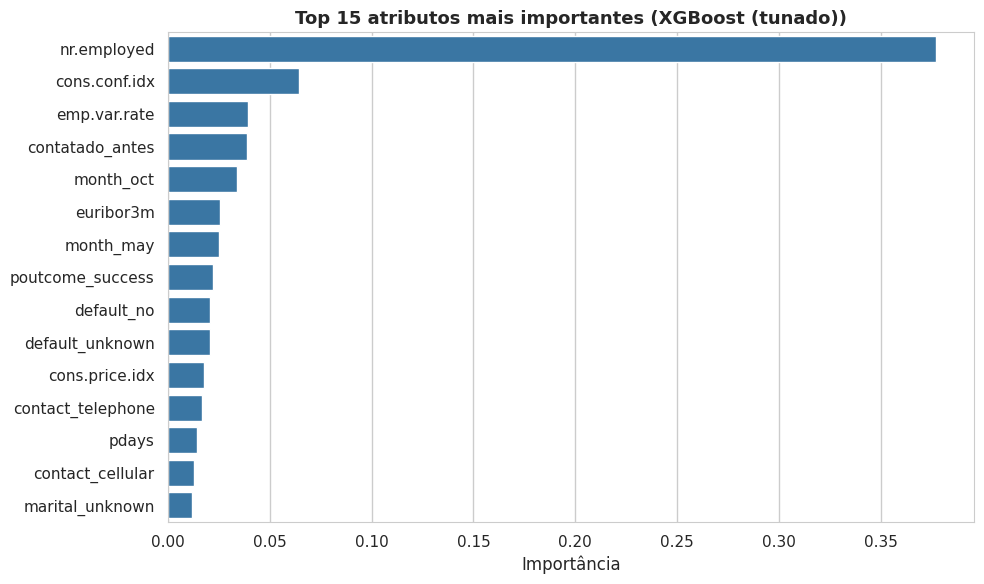

Top 10 features:
         feature  importance
     nr.employed    0.376889
   cons.conf.idx    0.064567
    emp.var.rate    0.039123
 contatado_antes    0.038633
       month_oct    0.033802
       euribor3m    0.025505
       month_may    0.025134
poutcome_success    0.022114
      default_no    0.020632
 default_unknown    0.020462


In [15]:
# Preferir o modelo ajustado, pois ele é a versão mais desenvolvida do XGBoost.
nome_importancia = "XGBoost (tunado)" if "XGBoost (tunado)" in treinados else "XGBoost"
modelo_importancia = treinados[nome_importancia]
pre = modelo_importancia.named_steps["pre"]
clf = modelo_importancia.named_steps["clf"]

cat_transformer = pre.named_transformers_["cat"]
cat_feature_names = cat_transformer.get_feature_names_out(cat_cols).tolist()
feature_names = num_cols + cat_feature_names

importances = clf.feature_importances_
if len(feature_names) != len(importances):
    raise ValueError(
        f"Número de nomes ({len(feature_names)}) diferente do número de importâncias ({len(importances)})."
    )

imp_df = pd.DataFrame({"feature": feature_names, "importance": importances})
imp_df = imp_df.sort_values("importance", ascending=False).head(15)

plt.figure(figsize=(10, 6))
sns.barplot(data=imp_df, y="feature", x="importance", color="#2878B5")
plt.title(f"Top 15 atributos mais importantes ({nome_importancia})", fontsize=13, fontweight="bold")
plt.xlabel("Importância")
plt.ylabel("")
plt.tight_layout()
plt.show()

print("Top 10 features:")
print(imp_df.head(10).to_string(index=False))


## 13. Comparação com o baseline (TDE 03)

No TDE 03, o melhor F1 no teste, com limiar 0,5, foi o **Naive Bayes Gaussiano (0,426)**. Os valores abaixo foram transcritos do notebook do TDE 03 e devem ser mantidos como referência histórica. A comparação mais justa pressupõe a mesma base, limpeza, divisão estratificada e semente — condições usadas nos dois notebooks.

Nesta seção, os modelos do TDE 04 serão consolidados, incluindo versões tunadas e o experimento com reamostragem. O ranking para escolha do candidato será baseado no **F1 da validação cruzada**, não no F1 do teste. O teste serve para reportar a estimativa final de generalização.


In [16]:
# Resultados do baseline do TDE 03 (F1 no teste, limiar 0,5).
baseline_f1 = {
    "Naive Bayes (TDE03)": 0.426,
    "k-NN (TDE03)": 0.390,
    "Random Forest (TDE03)": 0.371,
    "Árvore (TDE03)": 0.326,
    "Logistic (TDE03)": 0.318,
}

# Consolida todos os modelos do TDE 04 avaliados no mesmo conjunto de teste.
if resultados_adicionais:
    df_adicionais = pd.DataFrame(resultados_adicionais).set_index("Modelo")
    df_final = pd.concat([df_res, df_adicionais], axis=0)
else:
    df_final = df_res.copy()

# Inclui a estimativa de F1 na validação cruzada para orientar a seleção.
df_final["F1 (CV) "] = pd.Series(cv_scores_final)
df_final = df_final.sort_values("F1 (CV) ", ascending=False)

print("=" * 72)
print("COMPARAÇÃO DOS MODELOS DO TDE 04")
print("=" * 72)
display(df_final[["F1 (CV) ", "F1", "Precisão", "Recall", "ROC-AUC", "PR-AUC"]].style.format("{:.3f}").background_gradient(subset=["F1 (CV) ", "F1"], cmap="YlGn"))

melhor_cv = df_final["F1 (CV) "].idxmax()
melhor_f1_teste = df_final["F1"].idxmax()
print(f"Melhor candidato pelo F1 de validação cruzada: {melhor_cv} (CV={df_final.loc[melhor_cv, 'F1 (CV) ']:.3f})")
print(f"Maior F1 observado no teste (apenas relatório): {melhor_f1_teste} (teste={df_final.loc[melhor_f1_teste, 'F1']:.3f})")

print("\nBaseline do TDE 03:")
for nome, valor in baseline_f1.items():
    print(f"  {nome:30s}: {valor:.3f}")

print(f"\nReferência principal: Naive Bayes do TDE 03 = {baseline_f1['Naive Bayes (TDE03)']:.3f}")
print(
    "F1 no teste do candidato selecionado pela CV: "
    f"{df_final.loc[melhor_cv, 'F1']:.3f}"
)
print(
    "Diferença descritiva em relação ao baseline: "
    f"{df_final.loc[melhor_cv, 'F1'] - baseline_f1['Naive Bayes (TDE03)']:+.3f}"
)

print("\nResultados dos limiares otimizados (selecionados no treino):")
display(df_opt.style.format("{:.3f}"))


COMPARAÇÃO DOS MODELOS DO TDE 04


,F1 (CV),F1,Precisão,Recall,ROC-AUC,PR-AUC
Modelo,,,,,,
LightGBM (tunado),0.486,0.503,0.414,0.639,0.813,0.486
LightGBM,0.473,0.491,0.397,0.644,0.808,0.487
SVM (RBF balanced),0.472,0.126,0.489,0.072,0.785,0.396
XGBoost (tunado),0.469,0.486,0.387,0.651,0.815,0.487
Logistic (balanced),0.450,0.462,0.359,0.645,0.800,0.446
XGBoost,0.442,0.461,0.373,0.606,0.788,0.454
XGBoost + RandomOverSampler,0.436,0.467,0.383,0.598,0.786,0.452
Random Forest (balanced),0.367,0.376,0.546,0.287,0.782,0.422
MLP (Rede Neural),0.354,0.319,0.687,0.208,0.797,0.467


Melhor candidato pelo F1 de validação cruzada: LightGBM (tunado) (CV=0.486)
Maior F1 observado no teste (apenas relatório): LightGBM (tunado) (teste=0.503)

Baseline do TDE 03:
  Naive Bayes (TDE03)           : 0.426
  k-NN (TDE03)                  : 0.390
  Random Forest (TDE03)         : 0.371
  Árvore (TDE03)                : 0.326
  Logistic (TDE03)              : 0.318

Referência principal: Naive Bayes do TDE 03 = 0.426
F1 no teste do candidato selecionado pela CV: 0.503
Diferença descritiva em relação ao baseline: +0.077

Resultados dos limiares otimizados (selecionados no treino):


,Limiar escolhido no treino,F1 OOF no treino (limiar escolhido),"F1 teste (limiar 0,5)",F1 teste (limiar CV),Precisão teste (limiar CV),Recall teste (limiar CV)
Modelo,,,,,,
LightGBM,0.614,0.502,0.491,0.521,0.458,0.605
SVM (RBF balanced),0.305,0.492,0.126,0.523,0.468,0.593


## 14. Discussão dos resultados

Depois de executar todas as células, use as tabelas produzidas nas seções 7, 8, 9 e 13 para completar a discussão. Não conclua que um algoritmo é superior apenas por ser mais complexo ou por ter apresentado o maior F1 no conjunto de teste.

### Pontos que devem ser discutidos

1. **Efeito do desbalanceamento:** compare precisão, recall e F1 dos modelos balanceados com os resultados do baseline. Um aumento de recall pode vir acompanhado de queda de precisão.
2. **SVM e MLP:** registre os resultados reais desses dois algoritmos e compare-os com os modelos baseados em árvores e com a Regressão Logística.
3. **XGBoost e LightGBM:** compare os modelos originais e ajustados. Verifique se o ganho na validação cruzada também aparece no teste.
4. **Otimização do limiar:** explique que o limiar foi escolhido com previsões *out-of-fold* do treino. Compare o resultado no teste com o limiar padrão de 0,5.
5. **RandomOverSampler:** verifique se a replicação da classe minoritária melhorou F1 ou apenas alterou o equilíbrio entre precisão e recall.
6. **Explicabilidade:** interprete as variáveis mais importantes como associações aprendidas pelo modelo, não como relações causais.
7. **Generalização:** observe a diferença entre F1 de validação cruzada e F1 no teste. Diferenças grandes podem indicar instabilidade ou sobreajuste.

### Cuidados na interpretação

- Acurácia isolada é insuficiente porque aproximadamente 89% das observações pertencem à classe negativa.
- F1 depende do limiar. Por isso, informe sempre se o resultado usa limiar 0,5 ou limiar escolhido na validação.
- O conjunto de teste foi utilizado somente na avaliação. Não ajuste novamente os modelos olhando para os resultados do teste.
- O melhor F1 no teste é um resultado observado, não uma justificativa para escolher o modelo. A seleção deve considerar a validação cruzada e os objetivos do problema.
- `duration` permanece removida. A disponibilidade de outras variáveis deve ser coerente com o instante em que a previsão seria utilizada.

**Ao finalizar:** substitua afirmações genéricas por números reais impressos pelo notebook e explique por que o modelo escolhido é adequado ao problema.


## 15. Conclusão e próximos passos

Este TDE 04 amplia o baseline do TDE 03 com SVM, Rede Neural (MLP), XGBoost e LightGBM; compara estratégias de balanceamento; realiza ajuste de hiperparâmetros; e avalia a otimização do limiar sem utilizar o conjunto de teste para tomar decisões.

A conclusão final deve ser preenchida após a execução do notebook, informando:

- o modelo selecionado com base na validação cruzada;
- o F1, a precisão e o recall obtidos no teste;
- a diferença descritiva em relação ao melhor baseline do TDE 03 (F1 = 0,426);
- se a otimização do limiar e o `RandomOverSampler` trouxeram benefícios;
- as principais variáveis relevantes identificadas na análise de importância;
- limitações, especialmente o período histórico da base (2008–2010) e a disponibilidade operacional das variáveis.

### Próximos passos possíveis

1. Fazer validação temporal, respeitando a ordem cronológica dos contatos.
2. Avaliar calibração de probabilidades para decisões de negócio.
3. Analisar o desempenho por subgrupos e investigar falsos positivos e falsos negativos.
4. Aplicar SHAP para explicações globais e individuais, caso haja tempo e recursos computacionais.
5. Monitorar mudanças na distribuição dos dados e no desempenho caso o modelo seja utilizado em produção.

---

*Notebook desenvolvido para o TDE 04 – Disciplina de Inteligência Artificial.*
